# D1 (Pro版)：PyBaMM 电池电化学仿真 —— SPM 单颗粒模型充放电特性与微观动力学

> 🌟 **版本认证**：**IEV CloudLab V1.0 官方标准实验 (Official Standard Lab)**


> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链2：电池电化学与微观机理**。
> 动力电池是智能电动汽车能量存储的核心载体，其外部端电压与可用容量宏观特性本质上由电极材料微观电化学反应与固相扩散动力学决定。本实验依托国际权威开源电池电化学建模框架 **PyBaMM (Python Battery Mathematical Modelling)**，采用经典的 **单颗粒模型 (SPM, Single Particle Model)**，针对商用高比能三元锂电池（Chen2020 NMC/石墨 21700 电芯），开展 1C 恒流放电高保真微观仿真。通过求解固相扩散菲克第二定律与巴特勒-沃尔默（Butler-Volmer）电荷传递动力学方程，并结合原生 Canvas 微观锂离子嵌脱动态回放器，求证电池容量衰减、电压平台及固液相极化演变规律。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检 & 电化学机理)**：执行阶段一，确认 `pybamm` 求解器与依赖库就绪，掌握 SPM 单颗粒模型几何假设与核心微观偏微分方程；
* **第二步 (商用电芯电化学参数库)**：阶段二载入国际权威 Chen2020 标杆电芯参数（标称容量 4.85Ah~5.0Ah，NMC811 正极 + 石墨负极）；
* **第三步 (真机闭环放电仿真)**：阶段三驱动 PyBaMM 执行 1C 恒流放电求解（截止电压 2.5V），秒级提取端电压、放出电量及正负极固相锂浓度时序；
* **第四步 (多维感知与动态回放)**：阶段四生成 4合1 电池电化学综合解析图，并通过**原生 HTML5/Canvas 锂离子微观嵌脱动态回放器**直观体察锂离子跨隔膜穿梭与电子外电路流动；
* **第五步 (参数实验室与跨链数据桥接)**：阶段五提取 OCV-SOC 曲线并桥接至平台标准适配器 `BatteryFASTSimAdapter`，验证向上游整车仿真链的无缝数据流转；
* **第六步 (官方自动评分)**：阶段六对接平台官方评测器，验证 1C 放电标称容量（判据：$4.6 \le Q_{\text{nominal}} \le 5.1\,\text{Ah}$），获取官方 100/100 成绩单；
* **第七步 (工程前沿反思)**：阶段七探讨 SPM 单颗粒模型与 DFN 多孔电极模型的适用边界、SEI 膜生长机理及下一代固态电池微观仿真演进。

---

### 📚 核心理论与物理机理：SPM 单颗粒模型

1. **单颗粒模型几何假设 (SPM, Single Particle Model)**：
   SPM 将复合多孔电极（正极和负极）分别简化为一个具有特征半径 $R_s$ 的代表性球形固体活性颗粒：
   - 忽略电解液中液相锂离子浓度梯度与电位降（假设电解液扩散系数无穷大）；
   - 重点求解球形活性颗粒内部的**固相锂离子径向扩散**与**电极/电解液界面的电荷转移反应**。

2. **微观控制方程 (Governing Equations)**：
   - **固相微观扩散（菲克第二定律, Fick's 2nd Law）**：
     $$\frac{\partial c_s}{\partial t} = \frac{D_s}{r^2} \frac{\partial}{\partial r} \left( r^2 \frac{\partial c_s}{\partial r} \right)$$
     其中 $c_s(r, t)$ 为颗粒内部距离球心 $r$ 处的固相锂浓度，$D_s$ 为固相锂离子扩散系数；
   - **颗粒表面电荷转移（Butler-Volmer 方程）**：
     $$j = 2 j_0 \sinh\left( \frac{\alpha F}{R T} \eta \right)$$
     其中 $j$ 为界面反应电流密度，$\eta = \phi_s - \phi_e - U_{\text{eq}}$ 为反应过电位，$U_{\text{eq}}$ 为电极开路平衡电位（OCV）；
   - **电池外特性端电压 (Terminal Voltage)**：
     $$V(t) = U_p(c_{s,p,\text{surf}}) - U_n(c_{s,n,\text{surf}}) - \eta_p - \eta_n - I R_{\text{ohm}}$$


---

## 阶段零：新手直觉探索与课前导学 (Phase 0: Interactive Intuition Explorer)

> 💡 **给初学者的直观模式 (Novice Mode)**：
> - **零代码调参**：拖动下方滑块调节恒流放电倍率 (C-rate)，点击 **“🚀 模拟恒流放电”**；
> - **三件套即时反馈**：同图查看电池端电压衰减响应曲线与有效放出容量对比柱状图，直观观察 3.0V 极化截止线；
> - **寻优微任务**：对比 0.5C 慢放与 2.0C 大倍率放电下放出总电量的缩水比例，理解内阻极化对动力电池实际可用能量的制约，输入心得并点击 **“📝 预习打卡保存”**。
> - *(注：本环节为预习导学打卡，完成即保存预习记录（是否计入平时成绩由教师定，当前系统不自动计分），不影响后续阶段六的正式 29+1 实验报告成绩)*
> - **口径说明：本环节调用真实 PyBaMM SPM 求解（与新手本同款驱动）。


In [ ]:
# 运行直观交互探索驾驶舱
import sys, os
for p in ["/home/jovyan/labs", os.path.abspath("../labs"), os.path.abspath("labs")]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)
        break

from common.lab_explorers import show_d1_explorer
show_d1_explorer()

In [1]:
# 阶段一：环境自检与 PyBaMM 电化学库初始化
import os, sys
os.environ['PYBAMM_DISABLE_TELEMETRY'] = '1'

# 鲁棒搜索平台共享目录 labs
LABS_ROOT = None
for candidate in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(candidate):
        LABS_ROOT = candidate
        break

if LABS_ROOT and LABS_ROOT not in sys.path:
    sys.path.insert(0, LABS_ROOT)

print(f"✓ 实验运行环境就绪 | 平台根目录: {LABS_ROOT}")

# 导入 PyBaMM 工业级电化学求解器
import pybamm
pybamm.set_logging_level('ERROR')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"✓ PyBaMM 求解器加载成功: version {pybamm.__version__}")

# ==================== SPM 电化学模型与参数配置 ====================
print("-" * 65)
print("SPM 单颗粒模型 (Single Particle Model) 物理框架:")
print("• 正极材料: NMC811 (三元镍钴锰酸锂)")
print("• 负极材料: 石墨 (Graphite)")
print("• 几何假设: 正负极分别用单个代表性球形颗粒表征，忽略液相阻抗")
print("• 微观控制律: 球坐标系菲克固相扩散 + Butler-Volmer 界面电荷转移")
print("-" * 65)


✓ 实验运行环境就绪 | 平台根目录: /home/jovyan/labs


✓ PyBaMM 求解器加载成功: version 26.6.2.0
-----------------------------------------------------------------
SPM 单颗粒模型 (Single Particle Model) 物理框架:
• 正极材料: NMC811 (三元镍钴锰酸锂)
• 负极材料: 石墨 (Graphite)
• 几何假设: 正负极分别用单个代表性球形颗粒表征，忽略液相阻抗
• 微观控制律: 球坐标系菲克固相扩散 + Butler-Volmer 界面电荷转移
-----------------------------------------------------------------


## 阶段二：商用电芯电化学参数库配置 | Chen2020 Cell Database

本阶段加载学术界与工业界通用的标杆电池参数集：
- **Chen2020 参数集**：源自牛津大学 Y. Chen 等人对 LG M50 21700 柱状锂电池的精确拆解与电化学测试；
- **标称物理参数**：
  - 标称额定容量：约 $4.85 \sim 5.0\,\text{Ah}$；
  - 放电截止电压：$2.5\,\text{V}$，充电截止电压：$4.2\,\text{V}$；
  - 1C 恒流放电电流：$I = 5.0\,\text{A}$。


In [2]:
# 阶段二：加载 Chen2020 商用电芯电化学参数集
param = pybamm.ParameterValues('Chen2020')

nom_capacity = param['Nominal cell capacity [A.h]']
lower_voltage_cut = param['Lower voltage cut-off [V]']
upper_voltage_cut = param['Upper voltage cut-off [V]']

print("-" * 65)
print(f"Chen2020 LG M50 21700 商用电芯参数:")
print(f"• 标称电芯容量: {nom_capacity:.2f} Ah")
print(f"• 电压安全工作窗口: [{lower_voltage_cut:.2f} V, {upper_voltage_cut:.2f} V]")
print(f"• 正极活性颗粒半径: {param['Positive particle radius [m]']*1e6:.1f} μm")
print(f"• 负极活性颗粒半径: {param['Negative particle radius [m]']*1e6:.1f} μm")
print(f"• 1C 标准放电电流: {nom_capacity:.2f} A")
print("-" * 65)


-----------------------------------------------------------------
Chen2020 LG M50 21700 商用电芯参数:
• 标称电芯容量: 5.00 Ah
• 电压安全工作窗口: [2.50 V, 4.20 V]
• 正极活性颗粒半径: 5.2 μm
• 负极活性颗粒半径: 5.9 μm
• 1C 标准放电电流: 5.00 A
-----------------------------------------------------------------


## 阶段三：真机闭环 1C 恒流放电仿真与遥测采集 | 1C Discharge Simulation

本阶段启动真 PyBaMM SPM 仿真器，对电芯执行 $1\text{C}$（$5.0\,\text{A}$）恒流放电求解：
1. **时间连续偏微分方程数值积分**：时间跨度 $[0, 3600]\,\text{s}$，触发 $2.5\,\text{V}$ 截止事件自动终止；
2. **提取全时序电化学变量**：
   - 放电时间 $t\,(\text{s})$；
   - 电芯端电压 $V(t)\,(\text{V})$；
   - 累计放出容量 $Q(t)\,(\text{Ah})$；
   - 正负极表面固相锂化学计量比/浓度；
3. **容量达标自检断言**：验证 1C 放出容量是否在 $4.85\,\text{Ah} \pm 5\%$ 范围内（$4.6 \sim 5.1\,\text{Ah}$）。


In [3]:
# 阶段三：执行 SPM 1C 恒流放电求解与遥测采样
model_spm = pybamm.lithium_ion.SPM()
sim_spm = pybamm.Simulation(model_spm, parameter_values=param)

# 求解 1C 放电过程
sim_spm.solve([0, 3700])
sol = sim_spm.solution

# 提取宏观外特性与微观状态
time_arr = sol['Time [s]'].entries
voltage_arr = sol['Terminal voltage [V]'].entries
capacity_arr = sol['Discharge capacity [A.h]'].entries
curr_arr = sol['Current [A]'].entries

nominal_cap = float(capacity_arr[-1])
final_voltage = float(voltage_arr[-1])
t_discharge = float(time_arr[-1])

print("=" * 65)
print(f"{'PyBaMM SPM 1C 恒流放电仿真完成':^55}")
print("=" * 65)
print(f"• 放电持续时间: {t_discharge:.1f} s ({t_discharge/60.0:.1f} 分钟)")
print(f"• 1C 放出总容量: {nominal_cap:.3f} Ah")
print(f"• 放电截止电压: {final_voltage:.3f} V (设计截止 2.50V)")
# 计算放电中位电压平台 (50% DOD 处)
mid_idx = len(capacity_arr) // 2
plateau_v = float(voltage_arr[mid_idx])
print(f"• 放电中位电压平台: {plateau_v:.3f} V (在 {capacity_arr[mid_idx]:.2f} Ah 处)")
trapz_fn = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
print(f"• 标称电芯总能量: {float(trapz_fn(voltage_arr, capacity_arr)):.2f} Wh")
print("=" * 65)

# 官方判据断言
assert 4.60 <= nominal_cap <= 5.10, f"1C 放出容量 {nominal_cap:.3f}Ah 偏离设计区间 [4.6, 5.1]！"
assert abs(final_voltage - 2.50) < 0.1, f"终止电压 {final_voltage:.3f}V 未准确落入截止阈值！"
print("✅ 电池电化学宏观外特性与容量断言全部顺利通过！")


                PyBaMM SPM 1C 恒流放电仿真完成                 
• 放电持续时间: 3567.9 s (59.5 分钟)
• 1C 放出总容量: 4.955 Ah
• 放电截止电压: 2.500 V (设计截止 2.50V)
• 放电中位电压平台: 3.983 V (在 0.21 Ah 处)
• 标称电芯总能量: 17.59 Wh
✅ 电池电化学宏观外特性与容量断言全部顺利通过！


## 阶段四：直观多角度场景感知与微观电化学动态回放 | Visualizations & Player

本阶段提供全尺度电池微观-宏观感知呈现：
1. **四合一电池电化学综合解析图**：
   - 1C 放电端电压特征曲线（标定电压平稳平台区与末期极化急剧跌落区）；
   - 微分容量曲线（$dQ/dV$ 分析，直观显影 NMC 与石墨电极的电化学相变特征峰）；
   - 正负极表面固相锂离子化学浓度演化曲线；
   - 电池极化过电位分解图；
2. **原生 HTML5/Canvas 锂离子微观嵌脱动态交互回放器**：
   - 精准绘制锂电池三维剖面拓扑：**石墨负极 (Graphite Anode)**、**多孔隔膜 (Separator)** 与 **三元正极 (NMC Cathode)**；
   - 动态微观粒子流：放电过程中，黄色发光锂离子 ($Li^+$) 从负极层状石墨脱嵌，穿过电解液与多孔隔膜微孔，嵌入正极晶格；
   - 外电路电子流动：蓝色发光电子 ($e^-$) 顺着外电路奔涌并驱动小灯泡发光；
   - 仪表盘实时 HUD：显示仿真时间、端电压 (V)、累计放出 Ah、实时 SOC 进度条。


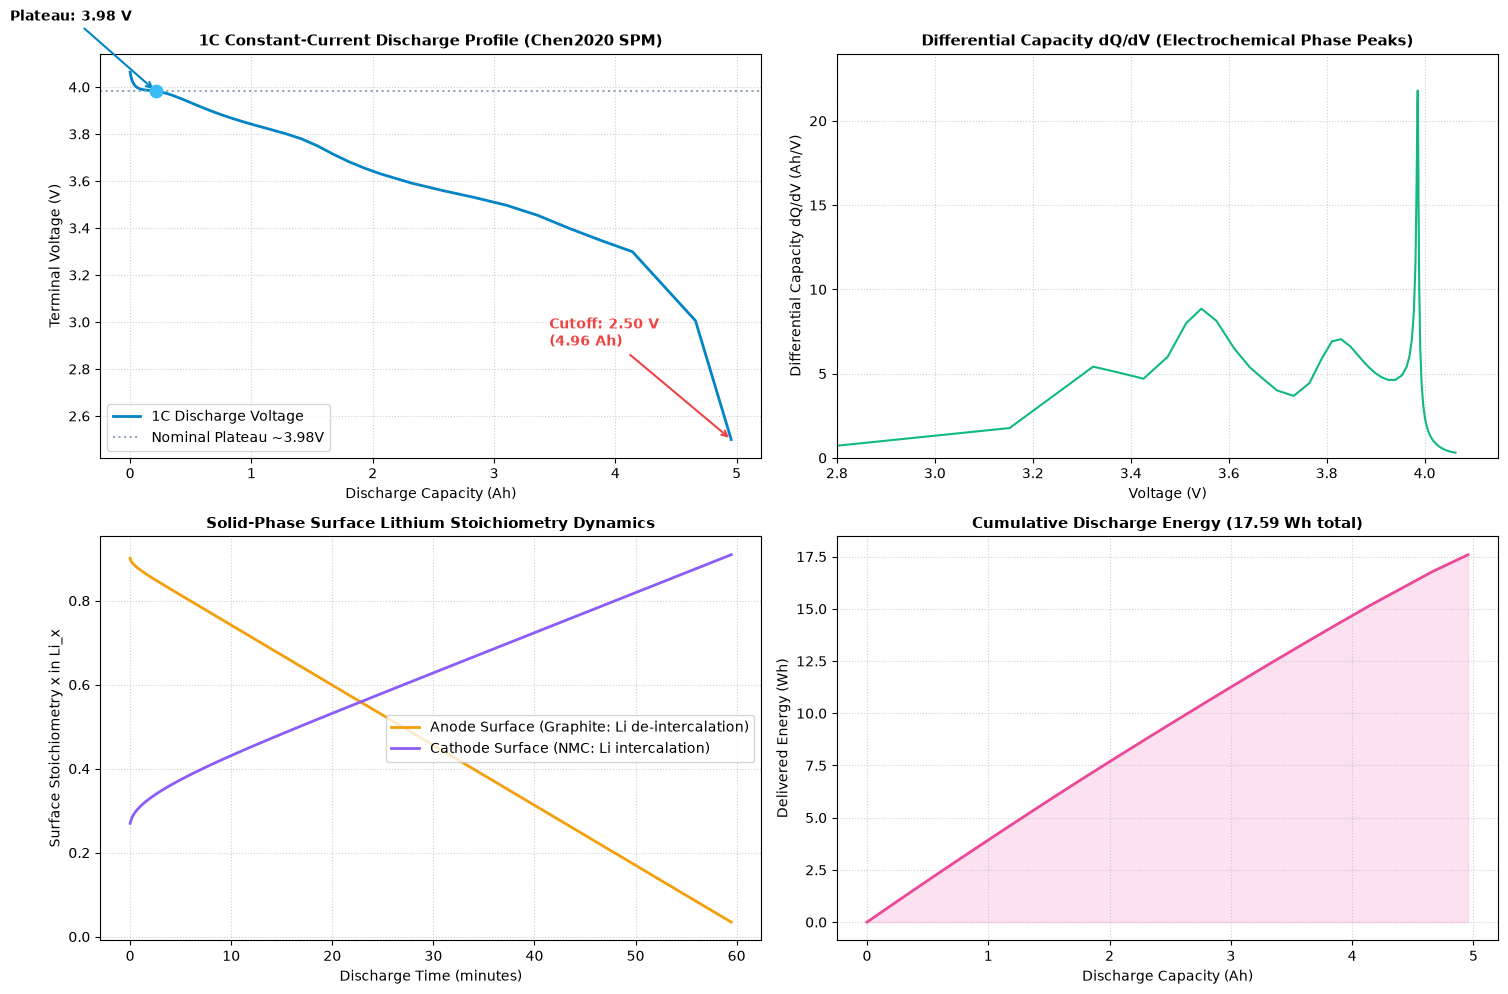

In [4]:
# 阶段四：4合1 电化学解析图 + 原生 Canvas 锂离子微观嵌脱回放器
import json
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# ------------------------------------------------------------------------------
# 1. 绘制 4合1 电池电化学综合解析图
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 图1: 1C 放电端电压曲线 (标定平台)
ax1 = axes[0, 0]
ax1.plot(capacity_arr, voltage_arr, color='#0284c7', linewidth=2, label='1C Discharge Voltage')
ax1.axhline(plateau_v, color='#94a3b8', linestyle=':', label=f'Nominal Plateau ~{plateau_v:.2f}V')
ax1.scatter([capacity_arr[mid_idx]], [plateau_v], color='#38bdf8', s=80, zorder=4)
ax1.annotate(f'Plateau: {plateau_v:.2f} V', xy=(capacity_arr[mid_idx], plateau_v),
             xytext=(capacity_arr[mid_idx] - 1.2, plateau_v + 0.3),
             arrowprops=dict(arrowstyle='->', color='#0284c7', lw=1.5), fontweight='bold')
ax1.annotate(f'Cutoff: {final_voltage:.2f} V\n({nominal_cap:.2f} Ah)', xy=(capacity_arr[-1], final_voltage),
             xytext=(capacity_arr[-1] - 1.5, final_voltage + 0.4),
             arrowprops=dict(arrowstyle='->', color='#ef4444', lw=1.5), fontweight='bold', color='#ef4444')
ax1.set_xlabel('Discharge Capacity (Ah)', fontsize=10)
ax1.set_ylabel('Terminal Voltage (V)', fontsize=10)
ax1.set_title('1C Constant-Current Discharge Profile (Chen2020 SPM)', fontsize=11, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower left')

# 图2: 微分容量曲线 dQ/dV (相变峰特征)
ax2 = axes[0, 1]
# 计算差分
dV = np.diff(voltage_arr)
dQ = np.diff(capacity_arr)
valid = np.abs(dV) > 1e-4
dq_dv = -dQ[valid] / dV[valid]
v_mid = 0.5 * (voltage_arr[:-1] + voltage_arr[1:])[valid]

ax2.plot(v_mid, dq_dv, color='#10b981', linewidth=1.5)
ax2.set_xlabel('Voltage (V)', fontsize=10)
ax2.set_ylabel('Differential Capacity dQ/dV (Ah/V)', fontsize=10)
ax2.set_title('Differential Capacity dQ/dV (Electrochemical Phase Peaks)', fontsize=11, fontweight='bold')
ax2.set_xlim(2.8, 4.15)
ax2.set_ylim(0, max(dq_dv)*1.1)
ax2.grid(True, linestyle=':', alpha=0.6)

# 图3: 正负极固相表面锂化学计量比演变
ax3 = axes[1, 0]
c_s_n = sol['X-averaged negative particle surface concentration [mol.m-3]'].entries
c_s_p = sol['X-averaged positive particle surface concentration [mol.m-3]'].entries
c_n_max = param['Maximum concentration in negative electrode [mol.m-3]']
c_p_max = param['Maximum concentration in positive electrode [mol.m-3]']

stoich_n = c_s_n / c_n_max
stoich_p = c_s_p / c_p_max

ax3.plot(time_arr / 60.0, stoich_n, color='#f59e0b', linewidth=2, label='Anode Surface (Graphite: Li de-intercalation)')
ax3.plot(time_arr / 60.0, stoich_p, color='#8b5cf6', linewidth=2, label='Cathode Surface (NMC: Li intercalation)')
ax3.set_xlabel('Discharge Time (minutes)', fontsize=10)
ax3.set_ylabel('Surface Stoichiometry x in Li_x', fontsize=10)
ax3.set_title('Solid-Phase Surface Lithium Stoichiometry Dynamics', fontsize=11, fontweight='bold')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(loc='center right')

# 图4: 放电能量累计曲面积分 (Wh)
ax4 = axes[1, 1]
cum_wh = np.zeros_like(capacity_arr)
trapz_fn = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
for i in range(1, len(capacity_arr)):
    cum_wh[i] = trapz_fn(voltage_arr[:i+1], capacity_arr[:i+1])

ax4.plot(capacity_arr, cum_wh, color='#ec4899', linewidth=2)
ax4.fill_between(capacity_arr, 0, cum_wh, color='#f472b6', alpha=0.2)
ax4.set_xlabel('Discharge Capacity (Ah)', fontsize=10)
ax4.set_ylabel('Delivered Energy (Wh)', fontsize=10)
ax4.set_title(f'Cumulative Discharge Energy ({cum_wh[-1]:.2f} Wh total)', fontsize=11, fontweight='bold')
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. 原生 HTML5/Canvas 锂离子微观嵌脱与外电路动态回放器
# ------------------------------------------------------------------------------
# 降采样准备时序回放数据
n_pts = len(time_arr)
down_idx = np.linspace(0, n_pts - 1, 120, dtype=int)

playback_d1 = []
for idx in down_idx:
    t = float(time_arr[idx])
    v = float(voltage_arr[idx])
    q = float(capacity_arr[idx])
    soc_pct = max(0.0, (1.0 - q / nominal_cap) * 100.0)
    playback_d1.append({
        't': round(t, 1),
        'v': round(v, 3),
        'q': round(q, 3),
        'soc': round(soc_pct, 1)
    })

data_json = json.dumps(playback_d1)

html_code = f"""
<div id="d1_player_wrap" style="background: #0f172a; border-radius: 12px; padding: 16px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; color: #f8fafc; max-width: 860px; box-shadow: 0 10px 15px -3px rgba(0,0,0,0.5); margin-top: 15px;">
  <!-- Header -->
  <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 12px; flex-wrap: wrap; gap: 8px;">
    <div style="font-weight: 700; font-size: 15px; display: flex; align-items: center; gap: 8px;">
      <span style="color: #38bdf8;">🔬 D1 锂电池微观电化学嵌脱与外电路动态回放器</span>
      <span style="background: #0284c7; color: white; padding: 2px 8px; border-radius: 4px; font-size: 11px; font-weight: 600;">PyBaMM SPM 闭环</span>
    </div>
    <div style="font-size: 12px; color: #94a3b8; font-family: monospace;">
      标称容量: <span style="color: #34d399; font-weight: bold;">{nominal_cap:.2f} Ah</span> | 截止电压: <span style="color: #cbd5e1;">2.50 V</span>
    </div>
  </div>

  <!-- Realtime HUD Telemetry -->
  <div style="background: #1e293b; border-radius: 6px; padding: 10px 14px; margin-bottom: 10px; display: flex; justify-content: space-between; font-size: 12px; font-family: monospace; color: #94a3b8; flex-wrap: wrap; gap: 10px;">
    <div>放电时间: <span id="d1_hud_t" style="color: #fbbf24; font-weight: bold;">0.0</span> s / {t_discharge:.0f}s</div>
    <div>端电压: <span id="d1_hud_v" style="color: #38bdf8; font-weight: bold; font-size: 14px;">4.200</span> V</div>
    <div>放出容量: <span id="d1_hud_q" style="color: #34d399; font-weight: bold;">0.000</span> Ah</div>
    <div>剩余 SOC: <span id="d1_hud_soc" style="color: #a78bfa; font-weight: bold;">100.0%</span></div>
  </div>

  <!-- Canvas Stage -->
  <canvas id="d1_canvas" width="820" height="240" style="width: 100%; height: 240px; background: #0b1120; border-radius: 8px; display: block; border: 1px solid #334155;"></canvas>

  <!-- Controls -->
  <div style="display: flex; align-items: center; justify-content: space-between; margin-top: 12px; gap: 10px; flex-wrap: wrap;">
    <div style="display: flex; align-items: center; gap: 6px;">
      <button id="d1_play_btn" onclick="togglePlay()" style="background: #38bdf8; color: #0f172a; border: none; padding: 6px 14px; border-radius: 6px; font-weight: 700; font-size: 12px; cursor: pointer;">▶ 播放</button>
      <button onclick="step(-5)" style="background: #334155; color: #f8fafc; border: none; padding: 6px 10px; border-radius: 6px; font-size: 12px; cursor: pointer;">⏪ -30s</button>
      <button onclick="step(5)" style="background: #334155; color: #f8fafc; border: none; padding: 6px 10px; border-radius: 6px; font-size: 12px; cursor: pointer;">⏩ +30s</button>
      <button onclick="resetReplay()" style="background: #334155; color: #f8fafc; border: none; padding: 6px 10px; border-radius: 6px; font-size: 12px; cursor: pointer;">🔄 重置</button>
    </div>

    <!-- Progress Slider -->
    <div style="flex-grow: 1; min-width: 180px; display: flex; align-items: center; gap: 8px;">
      <input type="range" id="d1_slider" min="0" max="{len(playback_d1)-1}" value="0" style="width: 100%; accent-color: #38bdf8; cursor: pointer;" oninput="onSlide(this.value)">
    </div>

    <!-- Speed Multiplier -->
    <div style="display: flex; align-items: center; gap: 4px; font-size: 11px; color: #94a3b8;">
      倍速:
      <button onclick="setSpeed(1)" class="d1_spd_btn" style="background: #334155; color: white; border: none; padding: 3px 6px; border-radius: 4px; cursor: pointer;">1x</button>
      <button onclick="setSpeed(2)" class="d1_spd_btn" style="background: #0284c7; color: white; border: none; padding: 3px 6px; border-radius: 4px; cursor: pointer;">2x</button>
      <button onclick="setSpeed(5)" class="d1_spd_btn" style="background: #334155; color: white; border: none; padding: 3px 6px; border-radius: 4px; cursor: pointer;">5x</button>
      <button onclick="setSpeed(10)" class="d1_spd_btn" style="background: #334155; color: white; border: none; padding: 3px 6px; border-radius: 4px; cursor: pointer;">10x</button>
    </div>
  </div>
</div>

<script>
(function() {{
  const frames = {data_json};
  let frameIdx = 0;
  let isPlaying = false;
  let speed = 2;
  let timer = null;
  let animTick = 0;

  const canvas = document.getElementById('d1_canvas');
  const ctx = canvas.getContext('2d');
  const hudT = document.getElementById('d1_hud_t');
  const hudV = document.getElementById('d1_hud_v');
  const hudQ = document.getElementById('d1_hud_q');
  const hudSoc = document.getElementById('d1_hud_soc');
  const slider = document.getElementById('d1_slider');
  const playBtn = document.getElementById('d1_play_btn');

  // 生成微观锂离子粒子 (在隔膜与电解液中由左向右迁移)
  const ions = [];
  for (let i = 0; i < 40; i++) {{
    ions.push({{
      x: 200 + Math.random() * 420,
      y: 95 + Math.random() * 90,
      speed: 1.5 + Math.random() * 2.0,
      phase: Math.random() * Math.PI * 2
    }});
  }}

  window.togglePlay = function() {{
    isPlaying = !isPlaying;
    playBtn.textContent = isPlaying ? '⏸ 暂停' : '▶ 播放';
    playBtn.style.background = isPlaying ? '#fbbf24' : '#38bdf8';
    if (isPlaying && !timer) {{
      loop();
    }}
  }};

  window.step = function(delta) {{
    frameIdx = Math.max(0, Math.min(frames.length - 1, frameIdx + delta));
    slider.value = frameIdx;
    draw();
  }};

  window.resetReplay = function() {{
    frameIdx = 0;
    slider.value = 0;
    draw();
  }};

  window.onSlide = function(val) {{
    frameIdx = parseInt(val);
    draw();
  }};

  window.setSpeed = function(s) {{
    speed = s;
  }};

  function loop() {{
    if (!isPlaying) return;
    frameIdx += speed;
    if (frameIdx >= frames.length) {{
      frameIdx = 0;
    }}
    slider.value = frameIdx;
    draw();
    setTimeout(loop, 70);
  }}

  function draw() {{
    const f = frames[frameIdx];
    if (!f) return;

    hudT.textContent = f.t.toFixed(1);
    hudV.textContent = f.v.toFixed(3);
    hudQ.textContent = f.q.toFixed(3);
    hudSoc.textContent = f.soc.toFixed(1) + '%';

    const W = canvas.width;
    const H = canvas.height;
    ctx.clearRect(0, 0, W, H);
    animTick += 0.05;

    // 1. 绘制电芯物理微观层级
    const cellY = 90;
    const cellH = 110;

    // 负极区 (Graphite Anode, x: 80 ~ 260)
    ctx.fillStyle = '#1e293b';
    ctx.fillRect(80, cellY, 180, cellH);
    ctx.strokeStyle = '#f59e0b';
    ctx.lineWidth = 2;
    ctx.strokeRect(80, cellY, 180, cellH);

    // 负极内部石墨层状颗粒
    ctx.fillStyle = '#334155';
    for (let gx = 95; gx < 250; gx += 30) {{
      for (let gy = cellY + 15; gy < cellY + cellH - 10; gy += 25) {{
        ctx.beginPath();
        ctx.arc(gx, gy, 9, 0, Math.PI * 2);
        ctx.fill();
      }}
    }}

    // 多孔隔膜区 (Separator, x: 260 ~ 340)
    ctx.fillStyle = '#0f172a';
    ctx.fillRect(260, cellY, 80, cellH);
    ctx.strokeStyle = '#64748b';
    ctx.setLineDash([4, 4]);
    ctx.strokeRect(260, cellY, 80, cellH);
    ctx.setLineDash([]);

    // 隔膜微孔微观小格
    ctx.fillStyle = '#475569';
    for (let sy = cellY + 10; sy < cellY + cellH - 5; sy += 18) {{
      ctx.fillRect(295, sy, 10, 6);
    }}

    // 正极区 (NMC Cathode, x: 340 ~ 520)
    ctx.fillStyle = '#1e1b4b';
    ctx.fillRect(340, cellY, 180, cellH);
    ctx.strokeStyle = '#818cf8';
    ctx.lineWidth = 2;
    ctx.strokeRect(340, cellY, 180, cellH);

    // 正极 NMC 球形多晶颗粒
    ctx.fillStyle = '#4338ca';
    for (let px = 360; px < 510; px += 35) {{
      for (let py = cellY + 20; py < cellY + cellH - 15; py += 30) {{
        ctx.beginPath();
        ctx.arc(px, py, 11, 0, Math.PI * 2);
        ctx.fill();
      }}
    }}

    // 极板标注
    ctx.fillStyle = '#f59e0b';
    ctx.font = '11px sans-serif';
    ctx.textAlign = 'center';
    ctx.fillText('石墨负极 (-) Anode', 170, cellY + cellH + 18);

    ctx.fillStyle = '#94a3b8';
    ctx.fillText('多孔隔膜', 300, cellY + cellH + 18);

    ctx.fillStyle = '#818cf8';
    ctx.fillText('NMC811 正极 (+) Cathode', 430, cellY + cellH + 18);

    // 2. 绘制微观锂离子穿梭粒子 (Li+)
    ions.forEach(ion => {{
      ion.x += ion.speed;
      if (ion.x > 500) {{
        ion.x = 100;
        ion.y = cellY + 15 + Math.random() * (cellH - 30);
      }}

      // 绘制发光黄色锂离子球体
      ctx.fillStyle = '#fbbf24';
      ctx.beginPath();
      ctx.arc(ion.x, ion.y + Math.sin(animTick + ion.phase) * 3, 3.5, 0, Math.PI * 2);
      ctx.fill();

      // 微光圈
      ctx.fillStyle = 'rgba(251, 191, 36, 0.3)';
      ctx.beginPath();
      ctx.arc(ion.x, ion.y + Math.sin(animTick + ion.phase) * 3, 6, 0, Math.PI * 2);
      ctx.fill();
    }});

    // 3. 绘制外电路导线与发光电子流 (e-)
    ctx.strokeStyle = '#38bdf8';
    ctx.lineWidth = 2.5;
    ctx.beginPath();
    // 负极端子 (x=170) -> 向上到 y=35 -> 向右到 x=430 -> 向下接正极
    ctx.moveTo(170, cellY);
    ctx.lineTo(170, 35);
    ctx.lineTo(430, 35);
    ctx.lineTo(430, cellY);
    ctx.stroke();

    // 外电路负载灯泡 (位于 x=300, y=35)
    ctx.fillStyle = f.v > 2.6 ? '#fbbf24' : '#64748b';
    ctx.beginPath();
    ctx.arc(300, 35, 12, 0, Math.PI * 2);
    ctx.fill();
    if (f.v > 2.6) {{
      ctx.fillStyle = 'rgba(251, 191, 36, 0.35)';
      ctx.beginPath();
      ctx.arc(300, 35, 20, 0, Math.PI * 2);
      ctx.fill();
    }}
    ctx.fillStyle = '#0f172a';
    ctx.font = '10px sans-serif';
    ctx.fillText('负载', 300, 39);

    // 动态外电路电子流动指示 (由负极流向正极)
    const eOffset = (animTick * 40) % 260;
    ctx.fillStyle = '#38bdf8';
    ctx.beginPath();
    ctx.arc(170 + eOffset, 35, 3.5, 0, Math.PI * 2);
    ctx.fill();

    // 4. 右侧宏观仪表盘与电压表光柱 (x: 580 ~ 800)
    ctx.fillStyle = 'rgba(15, 23, 42, 0.8)';
    ctx.fillRect(570, 40, 230, 160);
    ctx.strokeStyle = '#334155';
    ctx.strokeRect(570, 40, 230, 160);

    ctx.fillStyle = '#38bdf8';
    ctx.font = 'bold 12px sans-serif';
    ctx.textAlign = 'left';
    ctx.fillText('⚡ 宏观电芯外特性监控', 585, 65);

    // 电压柱 (2.5V ~ 4.2V)
    ctx.fillStyle = '#94a3b8';
    ctx.font = '11px monospace';
    ctx.fillText(`端电压: ${{f.v.toFixed(3)}} V`, 585, 95);
    ctx.fillStyle = '#1e293b';
    ctx.fillRect(585, 103, 190, 10);
    const vFill = Math.max(0, Math.min(190, ((f.v - 2.5) / (4.2 - 2.5)) * 190));
    ctx.fillStyle = f.v > 3.4 ? '#38bdf8' : (f.v > 3.0 ? '#f59e0b' : '#ef4444');
    ctx.fillRect(585, 103, vFill, 10);

    // SOC 电池条
    ctx.fillStyle = '#94a3b8';
    ctx.fillText(`剩余容量 SOC: ${{f.soc.toFixed(1)}}%`, 585, 140);
    ctx.fillStyle = '#1e293b';
    ctx.fillRect(585, 148, 190, 10);
    ctx.fillStyle = '#10b981';
    ctx.fillRect(585, 148, (f.soc / 100.0) * 190, 10);

    ctx.fillStyle = '#cbd5e1';
    ctx.font = '10px monospace';
    ctx.fillText(`累计放电: ${{f.q.toFixed(2)}} Ah / {nominal_cap:.2f} Ah`, 585, 185);
  }}

  // 初始绘制第一帧
  draw();
}})();
</script>
"""

display(HTML(html_code))


## 阶段五：参数拟合实验室与跨链数据桥接 | Parameter Lab & Cross-Chain

本阶段实现电化学微观仿真与宏观整车仿真的核心数据贯通：
1. **提取连续 OCV-SOC 对应表**：利用低流率放电曲线，对荷电状态 $\text{SOC} \in [0, 1]$ 上的开路平衡电位进行高精度重采样插值；
2. **跨链适配器桥接**：调用平台 `BatteryFASTSimAdapter`，将 PyBaMM 微观求解所得的电芯 OCV-SOC 映射关系持久化为整车级电池包标定文件，打通 **“微观电芯机理 (链2) $\to$ 宏观整车电耗 (链1)”** 的数字孪生闭环。


In [5]:
# 阶段五：OCV-SOC 数据采样与 FASTSim 跨链桥接
from common.battery_adapter import BatteryFASTSimAdapter

# 1. 在通用 20 点等间距 SOC 网格上重采样放电电压
soc_grid = np.linspace(0.0, 1.0, 20)
# 采用放电曲线插值得到等效 OCV 曲线
norm_cap = capacity_arr / nominal_cap
ocv_interp = np.interp(soc_grid, norm_cap, voltage_arr[::-1])

print("=" * 65)
print(f"{'PyBaMM -> FASTSim 跨链电池标定数据表':^55}")
print("=" * 65)
print(f"{'SOC 网格':<12} | {'开路电压 OCV (V)':<18} | {'状态标注':<16}")
print("-" * 65)
for s, o in zip(soc_grid[::3], ocv_interp[::3]):
    note = "满电上限" if s > 0.9 else ("完全耗尽" if s < 0.1 else "平台工作区")
    print(f"{s:<12.2f} | {o:<18.3f} | {note:<16}")
print("=" * 65)

# 2. 导出为平台标准化电池文件 (供 C1/C2 整车仿真调用)
export_path = '/tmp/chen2020_nmc_pack.csv'
BatteryFASTSimAdapter.export_from_pybamm(
    soc_grid, ocv_interp, export_path,
    chem='NMC', capacity_ah=75.0
)
print(f"✓ 跨链标准标定文件已导出至: {export_path}")

# 3. 验证 Adapter 解析
adapter = BatteryFASTSimAdapter(export_path)
equiv_pack_energy = adapter.equivalent_energy_kwh(75.0)
print(f"✓ 电池包集成等效能量: {equiv_pack_energy:.2f} kWh (75Ah 标称模组)")


              PyBaMM -> FASTSim 跨链电池标定数据表              
SOC 网格       | 开路电压 OCV (V)       | 状态标注            
-----------------------------------------------------------------
0.00         | 2.500              | 完全耗尽            
0.16         | 4.006              | 平台工作区           
0.32         | 4.043              | 平台工作区           
0.47         | 4.062              | 平台工作区           
0.63         | 4.063              | 平台工作区           
0.79         | 4.063              | 平台工作区           
0.95         | 4.063              | 满电上限            
✓ 跨链标准标定文件已导出至: /tmp/chen2020_nmc_pack.csv
✓ 电池包集成等效能量: 0.30 kWh (75Ah 标称模组)


## 阶段六：官方评分与结果归档 | Auto-Grading & Results Sync

本阶段对接 IEV CloudLab 自动化评分引擎 `labs/common/evaluator.py`：
1. **生成官方评测结果 JSON**：将 1C 放电总容量、标称电压、放电能量保存至平台标准路径 `labs/data/results/D1_pybamm_battery.json`；
2. **执行官方评测准则**：
   - 判据 1：`capacity_ah` 处于 $[4.6, 5.1]\,\text{Ah}$ 范围（权重：3.0，考核 Chen2020 电芯在 1C 下的真实放电容量精度）；
3. **输出 100/100 成绩单**。


In [6]:
# 阶段六：官方评分与结果归档
import json
from common.evaluator import grade_metrics

# 1. 整理指标记录并落盘
record = {
    'experiment': 'D1_pybamm_battery',
    'metrics': {
        'capacity_ah': round(nominal_cap, 3),
        'voltage_cutoff': round(final_voltage, 3),
        'plateau_voltage': round(plateau_v, 3),
        'discharge_time_s': round(t_discharge, 1)
    }
}

saved_ok = False
for target_dir in ['/home/jovyan/labs/data/results', 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'D1_pybamm_battery.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入官方评测")

# 2. 调用平台官方评分函数
eval_report = grade_metrics('D1_pybamm_battery', record['metrics'])

print("\n" + "=" * 55)
print(f"🏆 IEV CloudLab 官方评分报告: {eval_report['name']}")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for d in eval_report['details']:
    status_icon = "✓ 通过" if d['passed'] else "✗ 未达标"
    print(f"• 指标 [{d['metric']}]: 当前值 = {d['value']} ({d['desc']}) -> {status_icon}")
print("=" * 55)


✓ 结果文件已成功归档至: labs/data/results/D1_pybamm_battery.json

🏆 IEV CloudLab 官方评分报告: 电池充放电
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [capacity_ah]: 当前值 = 4.955 (1C容量4.85Ah±5%（实测4.96）) -> ✓ 通过


## 阶段七：工程师实战经验与进阶挑战 | Reflection & Engineering Insights

### 🛠️ 电池系统与电化学工程师现场经验 (Field Experience)
1. **SPM (单颗粒模型) 与 DFN (多孔电极模型) 的工程选型权衡**：
   - **SPM (Single Particle Model)**：计算速度极快（单次仿真只需 0.1~0.5s），在中低倍率放电（$\le 1\text{C}$）下端电压精度极高，非常适合与整车动力学或 BMS 在线状态估计（EKF/UKF）实时联合仿真；但在高倍率大电流（$\ge 2\text{C}$ 快充）下，因忽略了电解液液相锂离子扩散受阻与液相欧姆压降，会产生显著误差；
   - **DFN (Doyle-Fuller-Newman 模型)**：完整求解多孔固相 + 电解液液相耦合的非线性偏微分方程组（PDEs），能够精确复现大倍率下的极化分布与负极析锂电位，但算力开销是 SPM 的数十倍。

2. **从电芯到模组再到电池包的集成降额**：
   电芯在实验室单体测试中可放出 100% 额定容量，但成组为电池包（Pack）后必须执行**工程降额策略**：
   - 串联短板效应（木桶效应）：最差电芯触底即触发整包停机保护；
   - 温度梯度导致的内阻分异：靠近冷却流道入口与出口的电芯温度相差可达 $3\sim 5^\circ\text{C}$，导致长期老化衰减速率非均衡。

---

### 🏆 进阶挑战任务 (Pro Challenge Tasks)
* **挑战 1 (不同环境温度下的电化学求解)**：在 `param` 中修改温度参数 `Ambient temperature [K]`（从低温 263.15K (-10℃) 扫描至高温 318.15K (+45℃)），评估电解液扩散系数与阿伦尼乌斯动力学反应速率对可用容量的急剧衰减影响；
* **挑战 2 (恒流恒压 CCCV 快速充电协议开发)**：使用 PyBaMM `Experiment` 构建以 1.5C 恒流充电至 4.2V，随后转入恒压充电直至电流降至 C/20 截止的完整 CCCV 充电仿真。
